In [3]:
from utils import readin_raw, find_fds_for_rhs, fuzzy_filter,turnListToString, writeBackTrainingData, convertToDataFrame

In [4]:
import pandas as pd

In [5]:
data = pd.read_csv('../dataset.csv')

In [6]:
data

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False
...,...,...,...,...,...,...,...
207,190,"airport_name, airport_elevation",airport_iata_code,mondialjoin.csv,False,True,False
208,191,"city_elevation, airport_name",airport_iata_code,mondialjoin.csv,False,True,False
209,192,"airport_name, language_percentage, city_name",airport_iata_code,mondialjoin.csv,False,True,False
210,193,airport_latitude,airport_longitude,mondialjoin.csv,False,True,False


In [7]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

model = SentenceTransformer("all-MiniLM-L6-v2")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [8]:
texts = ["cat", "dog", "machine leaadwdlnawdrninawdasdg"]
embeddings = model.encode(texts, normalize_embeddings=True)

sim = cosine_similarity(embeddings)

print(sim)

[[0.9999999  0.6606375  0.16261387]
 [0.6606375  1.         0.20980448]
 [0.16261387 0.20980448 1.0000002 ]]


In [9]:
gen_data = data[data['is_genuine']]
nongen_data = data[data['is_genuine'] == False]

In [10]:
def build_cosine_sim(row):
    lhs = row['lhs']
    rhs = row['rhs']
    texts = [lhs, rhs]
    embeddings = model.encode(texts, normalize_embeddings=True)
    sim = cosine_similarity(embeddings)
    return sim[0][1]

In [11]:
gen_similarites_unclean = gen_data.apply(build_cosine_sim, axis=1)

In [12]:
ungen_similarites_clean = nongen_data.apply(build_cosine_sim, axis=1)

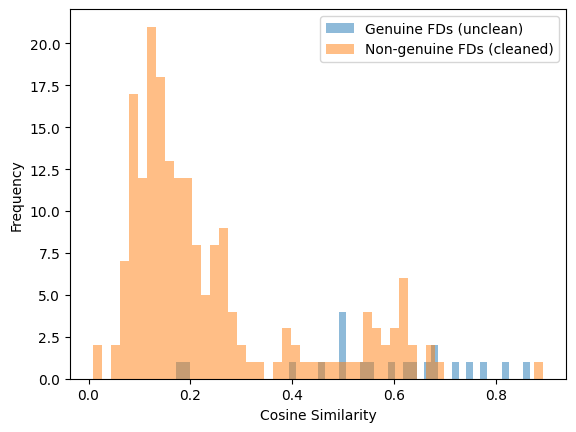

In [13]:
import matplotlib.pyplot as plt
plt.hist(gen_similarites_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_similarites_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [14]:
type(gen_similarites_unclean)

pandas.core.series.Series

In [15]:
texts = ['DepDelay', 'DepartureDelayGroups']
embeddings = model.encode(texts, normalize_embeddings=True)
cosine_similarity(embeddings)

array([[1.        , 0.17218277],
       [0.17218277, 1.        ]], dtype=float32)

In [16]:
import Levenshtein
print(Levenshtein.distance(texts[0], texts[1]))

12


In [17]:
def build_levenshtein(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    min_distance = float('inf')
    for lhs_elem in lhs:
        distance = Levenshtein.distance(lhs_elem, rhs)
        if distance < min_distance:
            min_distance = distance
    return min_distance

In [18]:
gen_leven_unclean = gen_data.apply(build_levenshtein, axis=1)
ungen_leven_clean = nongen_data.apply(build_levenshtein, axis=1)

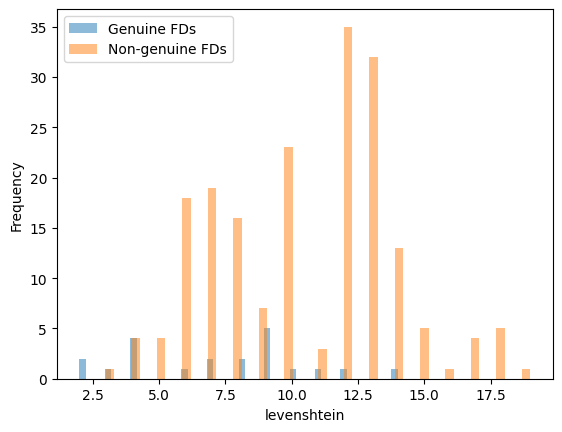

In [19]:
import matplotlib.pyplot as plt
plt.hist(gen_leven_unclean, bins=50, alpha=0.5, label='Genuine FDs')
plt.hist(ungen_leven_clean, bins=50, alpha=0.5, label='Non-genuine FDs')
plt.xlabel('levenshtein')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [20]:
def longest_common_substring(a: str, b: str) -> str:
    if not a or not b:
        return ""

    dp = [0] * (len(b) + 1)
    best_len = 0
    best_end = 0 

    for i in range(1, len(a) + 1):
        prev_diag = 0
        for j in range(1, len(b) + 1):
            tmp = dp[j]
            if a[i - 1] == b[j - 1]:
                dp[j] = prev_diag + 1
                if dp[j] > best_len:
                    best_len = dp[j]
                    best_end = i
            else:
                dp[j] = 0
            prev_diag = tmp

    return a[best_end - best_len:best_end]



In [21]:
def build_lcs(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    max_distance = 0
    for lhs_elem in lhs:
        distance = len(longest_common_substring(lhs_elem, rhs))
        if distance > max_distance:
            max_distance = distance
    return max_distance

In [22]:
gen_lcs_unclean = gen_data.apply(build_lcs, axis=1)
ungen_lcs_clean = nongen_data.apply(build_lcs, axis=1)

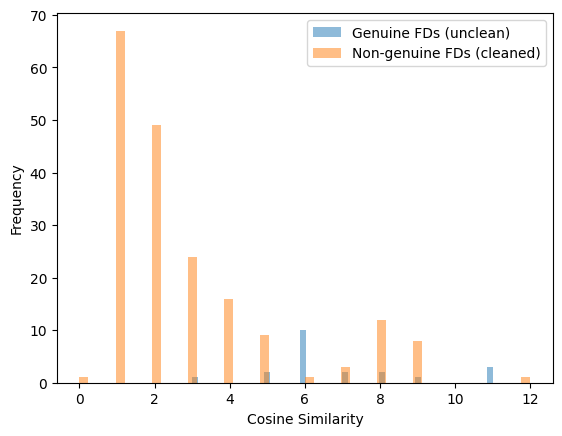

In [23]:
import matplotlib.pyplot as plt
plt.hist(gen_lcs_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_lcs_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [24]:
df = pd.DataFrame()

In [25]:
df['cosine_sim'] = pd.concat([gen_similarites_unclean, ungen_similarites_clean], ignore_index=True)
df['lcs'] = pd.concat([gen_lcs_unclean, ungen_lcs_clean], ignore_index=True)
df['leven'] = pd.concat([gen_leven_unclean, ungen_leven_clean], ignore_index=True)
df['is_genuine'] = [True] * len(gen_similarites_unclean) + [False] * len(ungen_similarites_clean)

In [26]:
df

,cosine_sim,lcs,leven,is_genuine
0,0.681850,6,2,True
1,0.640750,6,9,True
2,0.620726,6,2,True
3,0.503650,6,9,True
4,0.191531,3,14,True
...,...,...,...,...
207,0.613061,8,7,False
208,0.562231,8,7,False
209,0.559326,8,7,False
210,0.893999,9,3,False


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

X = df[["cosine_sim", "lcs", "leven"]]
y = df["is_genuine"]

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # important for classification
)


In [29]:
clf = DecisionTreeClassifier(
    max_depth=5,        # prevents overfitting
    min_samples_leaf=5, # smoother splits
    random_state=42
)

clf.fit(X_train, y_train)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [30]:
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.8604651162790697
              precision    recall  f1-score   support

       False       0.92      0.92      0.92        39
        True       0.25      0.25      0.25         4

    accuracy                           0.86        43
   macro avg       0.59      0.59      0.59        43
weighted avg       0.86      0.86      0.86        43



In [31]:
import pandas as pd

importance = pd.Series(
    clf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)


cosine_sim    0.640481
leven         0.189566
lcs           0.169953
dtype: float64


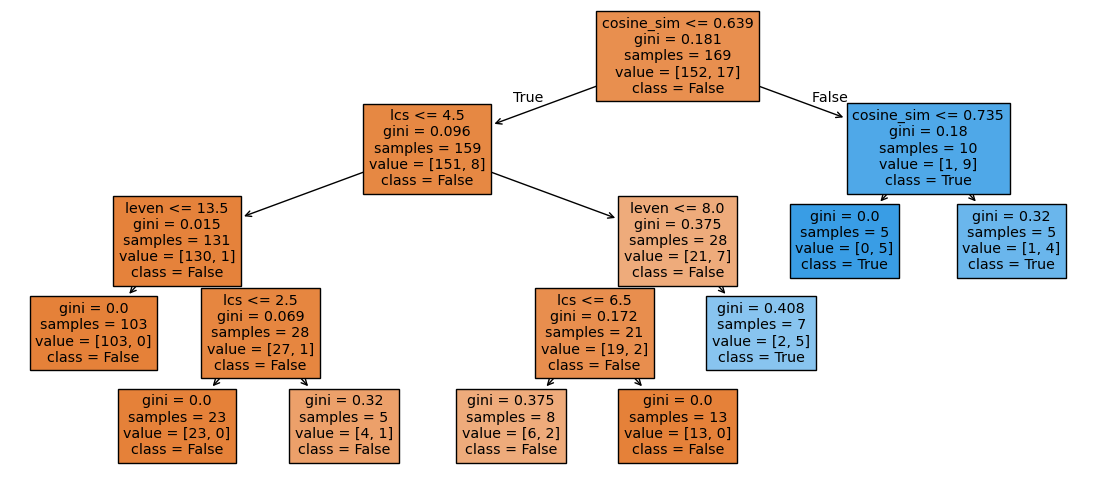

In [32]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plot_tree(
    clf,
    feature_names=X.columns,
    class_names=["False", "True"],
    filled=True
)
plt.show()


In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [34]:
clf = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",  # helpful if classes are imbalanced
    random_state=42
)

clf.fit(X_train_scaled, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [35]:
y_pred = clf.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.7209302325581395
              precision    recall  f1-score   support

       False       1.00      0.69      0.82        39
        True       0.25      1.00      0.40         4

    accuracy                           0.72        43
   macro avg       0.62      0.85      0.61        43
weighted avg       0.93      0.72      0.78        43



In [36]:
y_pred

array([False, False, False, False,  True,  True, False, False,  True,
       False, False, False,  True, False, False,  True,  True, False,
       False, False, False, False,  True, False, False, False, False,
        True,  True, False,  True,  True, False, False,  True,  True,
       False, False,  True, False,  True,  True, False])

In [49]:
raw_texts = ['DepDelay', 'DepartureDelayGroups']
embeddings = model.encode(raw_texts, normalize_embeddings=True)
cosine_similarity(embeddings)

array([[1.        , 0.17218277],
       [0.17218277, 1.        ]], dtype=float32)

In [50]:
Levenshtein.distance(raw_texts[0], raw_texts[1])

12

In [51]:
longest_common_substring(raw_texts[0], raw_texts[1])

'Delay'

In [52]:
import re

CAMEL_CASE_PATTERN = re.compile(
    r'''
    [A-Z]+(?=[A-Z][a-z]) |   # Acronyms followed by Capitalized words
    [A-Z]?[a-z]+ |           # Capitalized or lowercase words
    [A-Z]+ |                 # All-caps words
    \d+                      # Numbers
    ''',
    re.VERBOSE
)

def camel_case_tokenize(text: str) -> list[str]:
    return CAMEL_CASE_PATTERN.findall(text)


In [53]:
texts = camel_case_tokenize(raw_texts[0]) + camel_case_tokenize(raw_texts[1])
print(texts)

['Dep', 'Delay', 'Departure', 'Delay', 'Groups']


In [54]:
embeddings = model.encode(texts, normalize_embeddings=True)
sim = cosine_similarity(embeddings)

In [55]:
sim

array([[0.9999999 , 0.23588943, 0.2667035 , 0.23588943, 0.23431677],
       [0.23588943, 1.        , 0.27791503, 1.        , 0.29369235],
       [0.2667035 , 0.27791503, 1.0000001 , 0.27791503, 0.26653334],
       [0.23588943, 1.        , 0.27791503, 1.        , 0.29369235],
       [0.23431677, 0.29369235, 0.26653334, 0.29369235, 0.99999994]],
      dtype=float32)

In [ ]:
import numpy as np
levenshteins = np.array([], dtype=np.int16)
for t1 in texts:
    row = []
    for t2 in texts:
        row.append(Levenshtein)